In [14]:
import numpy as np
from scipy.integrate import solve_ivp
#import plotly.graph_objects as go

In [ ]:


def dphi_dt(t, x, y, phi):
    return (v_x(t, x, y)*np.sin(phi)**2
            + (u_x(t, x, y) - v_y(t, x, y))*np.sin(phi)*np.cos(phi)
            - u_y(t, x, y)*np.cos(phi)**2)

def solve_one(phi0, T, n_pts=200):
    x0, y0 = 0, 0
    def func(t, w):
        x, y, phi = w
        return [u(t, x, y) + k*np.cos(phi),
                v(t, x, y) + k*np.sin(phi),
                dphi_dt(t, x, y, phi)]
    res = solve_ivp(func, (0, T), [x0, y0, phi0],
                    t_eval=np.linspace(0, T, n_pts), atol=1e-8, rtol=1e-8)
    x, y, phi = res.y
    return x, y
    
def iterate(range_phi0, range_T):
    losses = np.zeros((len(range_phi0), len(range_T)))
    xvals = np.empty((len(range_phi0), len(range_T)), dtype=object)
    yvals = np.empty((len(range_phi0), len(range_T)), dtype=object)
    for i,phi0 in enumerate(range_phi0):
        for j,T in enumerate(range_T):
            x,y = solve_one(phi0, T)
            loss = np.linalg.norm([x[-1]-A, y[-1]-B])
            xvals[i,j] = x
            yvals[i,j] = y
            losses[i,j] = loss
    return losses, xvals, yvals

def deepen(num, phi_init, T_init, h_phi0=1e-7, h_T=1e-7, pct_increase_stop=0.001, lmbda=0.5):
    trajectory = np.empty((num, 2), dtype=object) # x, y
    losses = np.empty(num, dtype=float)
    params = np.empty((num, 2), dtype=object)

    phi, T = phi_init, T_init
    c = 0
    pct = 1.0

    while c < num and pct >= pct_increase_stop:
        x, y = solve_one(phi, T)
        trajectory[c, 0] = x
        trajectory[c, 1] = y
        params[c, 0] = phi
        params[c, 1] = T
        r = np.array([x[-1] - A, y[-1] - B])
        losses[c] = np.linalg.norm(r)

        xp, yp = solve_one(phi + h_phi0, T)
        r_phi = np.array([xp[-1] - A, yp[-1] - B])
        xt, yt = solve_one(phi, T + h_T)
        r_T = np.array([xt[-1] - A, yt[-1] - B])

        J = np.column_stack([(r_phi - r) / h_phi0, (r_T - r) / h_T])
        delta = -np.linalg.pinv(J) @ r            # Newton step in (phi, T)
        phi, T = phi + lmbda * delta[0], max(T + lmbda * delta[1], 1e-3)

        pct = np.linalg.norm(delta) / max(np.linalg.norm([phi, T]), 1e-12)
        c += 1

    return trajectory, losses, params, c

/tmp/ipykernel_4119/180887556.py:14: RuntimeWarning: invalid value encountered in sqrt
  print('best angle:', np.arccos(0.5*(c/k + np.sqrt(2-c**2/k**2)))*180/np.pi, "deg")
/home/tobiasocula/Documents/bachelor thesis/venv/lib/python3.13/site-packages/scipy/integrate/_ivp/ivp.py:626: UserWarning: The following arguments have no effect for a chosen solver: `tolerance`.
  solver = method(fun, t0, y0, tf, vectorized=vectorized, **options)


best angle: nan deg


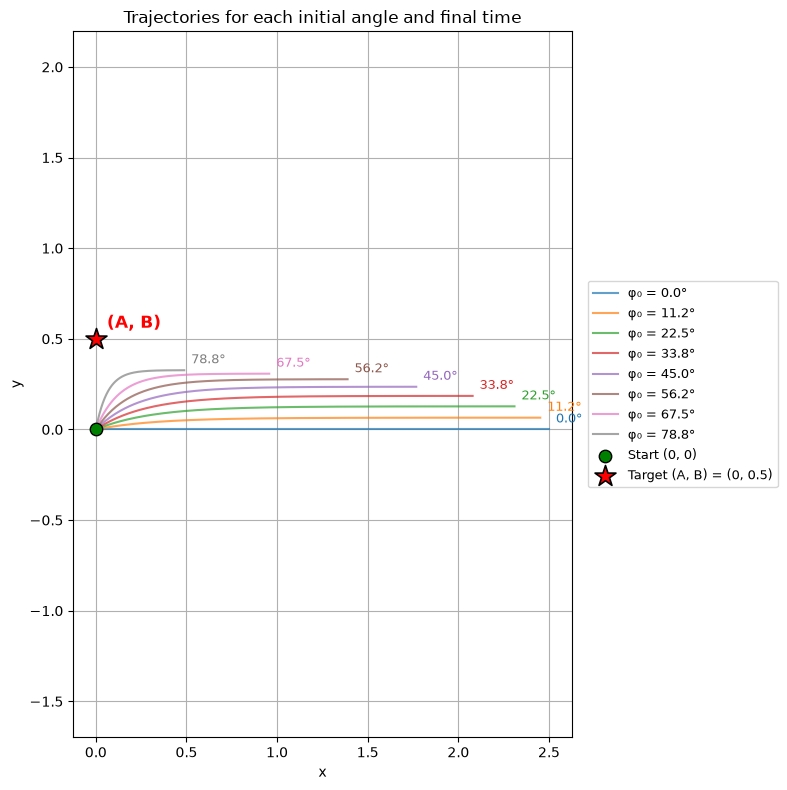

In [16]:
"""
RUN ITERATE FUNCTION AND PLOT TRAJECTORIES
"""

import matplotlib.pyplot as plt

# Initial position for every trajectory
x0, y0 = 0.0, 0.0

# Example parameter ranges; change these as needed
range_phi0 = np.linspace(0, 0.5*np.pi, 8, endpoint=False)
range_T = [2.5]

print('best angle:', np.arccos(0.5*(c/k + np.sqrt(2-c**2/k**2)))*180/np.pi, "deg")

losses, xvals, yvals = iterate(range_phi0, range_T)

fig, ax = plt.subplots(figsize=(8, 8))
for i, phi0 in enumerate(range_phi0):
    for j, T in enumerate(range_T):
        angle_deg = np.degrees(phi0)

        # Include T in the label only if several final times are plotted
        if len(range_T) > 1:
            label = f"φ₀ = {angle_deg:.1f}°, T = {T:g}"
        else:
            label = f"φ₀ = {angle_deg:.1f}°"

        (line,) = ax.plot(xvals[i, j], yvals[i, j], alpha=0.7, label=label)

        # Text label at the end of the trajectory, matching the line color
        ax.annotate(f"{angle_deg:.1f}°",
                    xy=(xvals[i, j][-1], yvals[i, j][-1]),
                    xytext=(5, 5), textcoords="offset points",
                    fontsize=9, color=line.get_color())

# Mark the start point (x0, y0)
ax.scatter([x0], [y0], color="green", s=80, marker="o",
           edgecolor="black", zorder=5, label=f"Start ({x0:g}, {y0:g})")

# Mark the target point (A, B)
ax.scatter([A], [B], color="red", s=250, marker="*",
           edgecolor="black", linewidths=1.2, zorder=6,
           label=f"Target (A, B) = ({A:g}, {B:g})")
ax.annotate("(A, B)", xy=(A, B), xytext=(8, 8),
            textcoords="offset points", fontsize=12,
            fontweight="bold", color="red", zorder=6)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Trajectories for each initial angle and final time")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(True)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9)
fig.tight_layout()
plt.show()

In [ ]:
from matplotlib import cm, colors

"""
u = -c
"""

c = 3
u = lambda t,x,y: -c
v = lambda t,x,y: 0.0
k = 10
A, B = 10, 10


phi_opt = 32.75  # degrees
deviation = 35.0  # degrees
phi0 = (phi_opt + deviation) / 180 * np.pi
T0 = 1.0

points_per_trajectory, losses, num_attempts, paths, phis_used, Ts_used = deepen(
    num=20, range_phi0=[phi0], range_T=[T0]
)
phis_used = phis_used[0, 0]  # list of phis
Ts_used = Ts_used[0, 0]      # list of Ts
attempts = paths[0, 0]       # list of (x, y) tuples, one per iteration
n = len(attempts)

fig, ax = plt.subplots(figsize=(10, 8))

cmap = cm.viridis
norm = colors.Normalize(vmin=1, vmax=max(num, 2))

# every iteration, colored by its iteration number and labelled with its phi
for k, ((x, y), phi_k) in enumerate(zip(attempts, phis_used)):
    for l, ((x, y), T_l) in enumerate(zip(attempts, Ts_used)):
        ax.plot(x, y, color=cmap(norm(k + 1)), lw=1.8, alpha=0.9,
                label=f"{k + 1}: φ = {180/np.pi*phi_k:.3f}°")

k = 0
for i,phi in enumerate(phis_used):
    for j,T in enumerate(Ts_used):
        x,y = paths[i,j]
        ax.plot(x, y, color=cmap(norm(k + 1)), lw=1.8, alpha=0.9,
                label=f"{k + 1}: φ = {180/np.pi*phi:.3f}°, T = {T:.3f}")
        k += 1

# start point and target
ax.plot(attempts[0][0][0], attempts[0][1][0], "go", markersize=8, label="Start")
ax.plot(A, B, "k*", markersize=14, label="Target (A, B)")

# colorbar for the iteration number
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, label="Iteration", fraction=0.046, pad=0.04)

ax.set_title(f"All {n} iterations, initial φ₀ = {180/np.pi*phi0:.2f}°, T₀ = {T0}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

# legend outside the axes, to the right of the colorbar
ax.legend(title="Iteration: φ used", loc="center left",
          bbox_to_anchor=(1.25, 0.5), fontsize=8)

fig.tight_layout()
plt.show()

TypeError: deepen() got an unexpected keyword argument 'range_phi0'

φ0=π/3, T=0.5, final loss=4.2853, num attempts=4
φ0=π/3, T=1.6, final loss=1.7304, num attempts=9
φ0=π/3, T=2.8, final loss=0.0083, num attempts=8
φ0=π/3, T=3.9, final loss=2.2407, num attempts=5
φ0=π/3, T=5.0, final loss=0.0196, num attempts=5
φ0=π/4, T=0.5, final loss=0.0378, num attempts=8
φ0=π/4, T=1.6, final loss=0.1753, num attempts=5
φ0=π/4, T=2.8, final loss=0.0025, num attempts=11
φ0=π/4, T=3.9, final loss=4.5576, num attempts=4
φ0=π/4, T=5.0, final loss=0.0531, num attempts=4
φ0=π/6, T=0.5, final loss=0.0169, num attempts=6
φ0=π/6, T=1.6, final loss=0.0158, num attempts=5
φ0=π/6, T=2.8, final loss=0.0257, num attempts=6
φ0=π/6, T=3.9, final loss=3.7277, num attempts=9
φ0=π/6, T=5.0, final loss=0.0142, num attempts=4


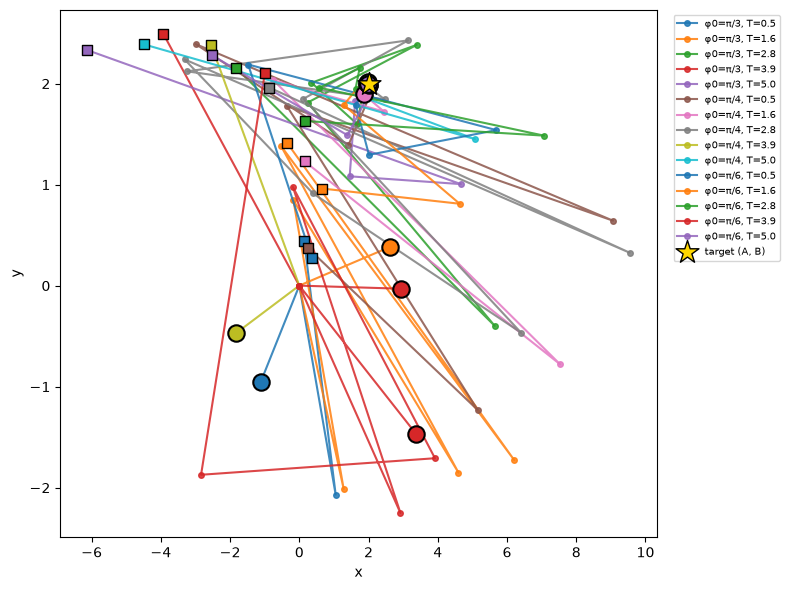

In [ ]:
range_phi0 = np.array([np.pi/n for n in [3, 4, 6]])
range_T = np.linspace(0.5, 5.0, 5)

points_per_trajectory, losses, num_attempts = deepen(50, range_phi0, range_T, lmbda=1.0)

cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(figsize=(8, 6))

for i, phi in enumerate(range_phi0):
    for j, T in enumerate(range_T):
        color = cmap((i * len(range_T) + j) % 10)
        xs = np.asarray(points_per_trajectory[i, j, 0])
        ys = np.asarray(points_per_trajectory[i, j, 1])

        print(f"φ0=π/{round(np.pi/phi)}, T={T:.1f}, final loss={losses[i,j][-1]:.4f}, num attempts={num_attempts[i,j]}")

        # line connecting successive iterates, with a dot at each iteration
        ax.plot(xs, ys, "-o", color=color, lw=1.5, markersize=4, alpha=0.85,
                label=f"φ0=π/{round(np.pi/phi)}, T={T:.1f}")

        # starting iterate (iteration 0) and final iterate, marked clearly
        ax.scatter(xs[0], ys[0], color=color, edgecolor="black", marker="s", s=60, zorder=4)
        ax.scatter(xs[-1], ys[-1], color=color, edgecolor="black", marker="o", s=140,
                   linewidth=1.5, zorder=5)

ax.scatter(A, B, marker="*", color="gold", edgecolor="black", s=300, zorder=6, label="target (A, B)")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

num attempts: 4


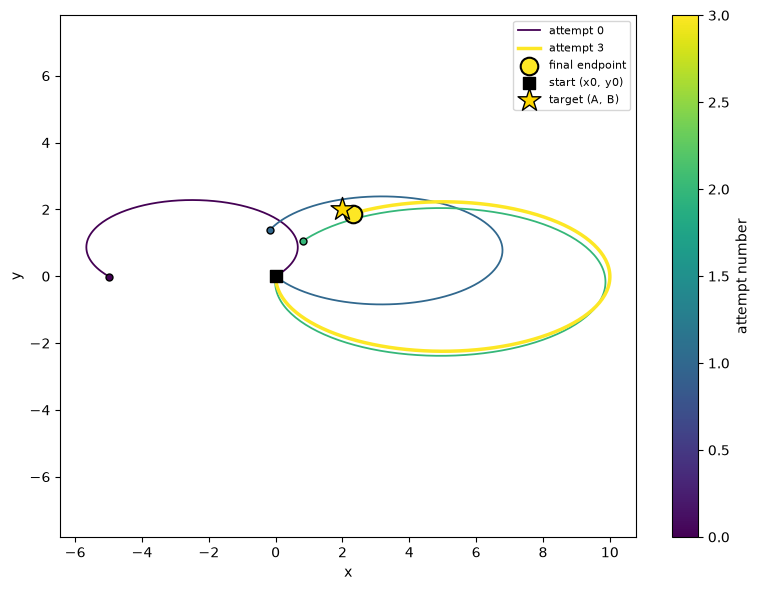

In [ ]:
points_per_trajectory, losses, num_attempts, paths, params = deepen(50, [np.pi/6], [10.0], lmbda=1.0)

paths = paths[0, 0]

n_att = len(attempts)

print('num attempts:', num_attempts[0,0])

cmap = plt.get_cmap("viridis")
fig, ax = plt.subplots(figsize=(8, 6))

for a, (x, y) in enumerate(attempts):
    color = cmap(a / max(n_att - 1, 1))
    is_last = (a == n_att - 1)
    ax.plot(x, y, "-", color=color, lw=2.5 if is_last else 1.3,
            label=f"attempt {a}" if (a == 0 or is_last) else None)
    ax.scatter(x[-1], y[-1], color=color, edgecolor="black", s=25, zorder=3)  # endpoint of each attempt

# clearly mark the final endpoint
xf, yf = attempts[-1][0][-1], attempts[-1][1][-1]
ax.scatter(xf, yf, color=cmap(1.0), edgecolor="black", s=160, linewidth=1.5, zorder=5, label="final endpoint")

ax.scatter(x0, y0, marker="s", color="black", s=80, zorder=6, label="start (x0, y0)")
ax.scatter(A, B, marker="*", color="gold", edgecolor="black", s=300, zorder=6, label="target (A, B)")

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, n_att - 1))
fig.colorbar(sm, ax=ax, label="attempt number")

ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_aspect("equal", adjustable="datalim")
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

params: [[1.1824605682261582 1.5]
 [np.float64(1.389956431309824) np.float64(0.8927792535471063)]
 [np.float64(1.4121227217046917) np.float64(0.6969156851840034)]
 [np.float64(1.3906566249136354) np.float64(0.604032253946758)]
 [np.float64(1.363575427781783) np.float64(0.5591069967908812)]
 [np.float64(1.3436582405910686) np.float64(0.5373599883338882)]
 [np.float64(1.3316670322558475) np.float64(0.5267598448308015)]
 [np.float64(1.3250968158292031) np.float64(0.5215458882398778)]
 [np.float64(1.3216590820425753) np.float64(0.5189631679851442)]
 [np.float64(1.3199009035693303) np.float64(0.5176782502483157)]
 [np.float64(1.3190118403037046) np.float64(0.5170374516873844)]
 [None None]
 [None None]
 [None None]
 [None None]
 [None None]
 [None None]
 [None None]
 [None None]
 [None None]]
phistar, Tstar: 1.3190118403037046 0.5170374516873844


NameError: name 'num' is not defined

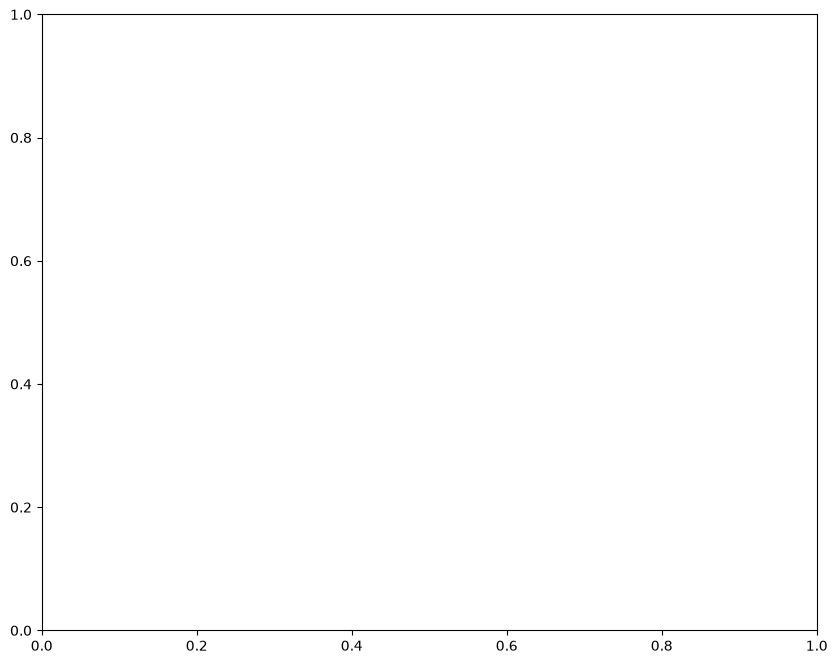

In [19]:
from matplotlib import cm, colors
from scipy.integrate import solve_ivp

"""
u = -y
"""

c = 3
u = lambda t,x,y: -y
v = lambda t,x,y: 0.0
k = 1
A, B = 0, 0.5
phi0 = 1.0 # 57 deg


phi_opt = 32.75  # degrees
deviation = 35.0  # degrees
phi0 = (phi_opt + deviation) / 180 * np.pi # initial guess for init angle

T0 = 1.5 # initial guess for final time

trajectory, losses, params, num_iters = deepen(
    num=20, phi_init=phi0, T_init=T0
)

print('params:', params)

Tstar = params[num_iters-1, 1]
phistar = params[num_iters-1, 0] # best ones according to algo
x_best, y_best = trajectory[-1]
#phi_best = np.atan2(y_best / x_best) if x_best != 0 else np.pi / 2
fig, ax = plt.subplots(figsize=(10, 8))

print('phistar, Tstar:', phistar, Tstar)

cmap = cm.viridis
norm = colors.Normalize(vmin=1, vmax=max(num, 2))

# every iteration, colored by its iteration number and labelled with its phi
k = 0
"""

ax.plot(x, y, color=cmap(norm(k + 1)), lw=1.8, alpha=0.9,
                label=f"{k + 1}: φ = {180/np.pi*phi:.3f}°, T = {T:.3f}")
        k += 1
        """
for k in range(num_iters):
    x, y = trajectory[k]
    phi_k, T_k = params[k, :]
    ax.plot(x, y, color=cmap(norm(k + 1)), lw=1.8, alpha=0.9,
            label=f"{k + 1}: φ = {180/np.pi*phi_k:.3f}°, T = {T_k:.3f}")

        

# start point and target
ax.plot(attempts[0][0][0], attempts[0][1][0], "go", markersize=8, label="Start")
ax.plot(A, B, "k*", markersize=14, label="Target (A, B)")

# colorbar for the iteration number
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, label="Iteration", fraction=0.046, pad=0.04)

ax.set_title(f"All {n} iterations, initial φ₀ = {180/np.pi*phi0:.2f}°, T₀ = {T0}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

"""actual best path (paper)
"""

t = np.linspace(0, Tstar, 200)
phi_best = np.arctan(t+np.tan(phistar))
y_best = 1/np.cos(phi_best)-1/np.cos(phistar)

def x_of_y(y, x):
       s = 1/np.cos(phistar)
       return (1 - y*(y + s)) / np.sqrt((y + s)**2 - 1)

sol_x = solve_ivp(x_of_y, (0, y_best[-1]), [0], t_eval=y_best)
x_best = sol_x.y[0]

ax.plot(x_best, y_best, "k--", lw=1.8, label="Optimal path (solve_ivp in y)")

# legend outside the axes, to the right of the colorbar
ax.legend(title="Iteration: φ used", loc="center left",
          bbox_to_anchor=(1.25, 0.5), fontsize=8)

fig.tight_layout()
plt.show()

/home/tobiasocula/Documents/bachelor thesis/venv/lib/python3.13/site-packages/scipy/integrate/_ivp/ivp.py:626: UserWarning: The following arguments have no effect for a chosen solver: `tolerance`.
  solver = method(fun, t0, y0, tf, vectorized=vectorized, **options)


params: [[1.0 1.5]
 [np.float64(0.9908523669836595) np.float64(1.6540379664856422)]
 [np.float64(0.9896155646018573) np.float64(1.7363431253464934)]
 [np.float64(0.9896556642619087) np.float64(1.7790057654478169)]
 [np.float64(0.9898248857355005) np.float64(1.800745040357041)]
 [np.float64(0.9899451706892479) np.float64(1.8117209642427081)]
 [np.float64(0.9900140462203456) np.float64(1.8172360672340981)]
 [np.float64(0.9900506450684484) np.float64(1.8200004773162783)]
 [np.float64(0.9900694820476531) np.float64(1.821384406299017)]
 [None None]]
phistar, Tstar: 0.9900694820476531 1.821384406299017
best time: 1.821384406299017


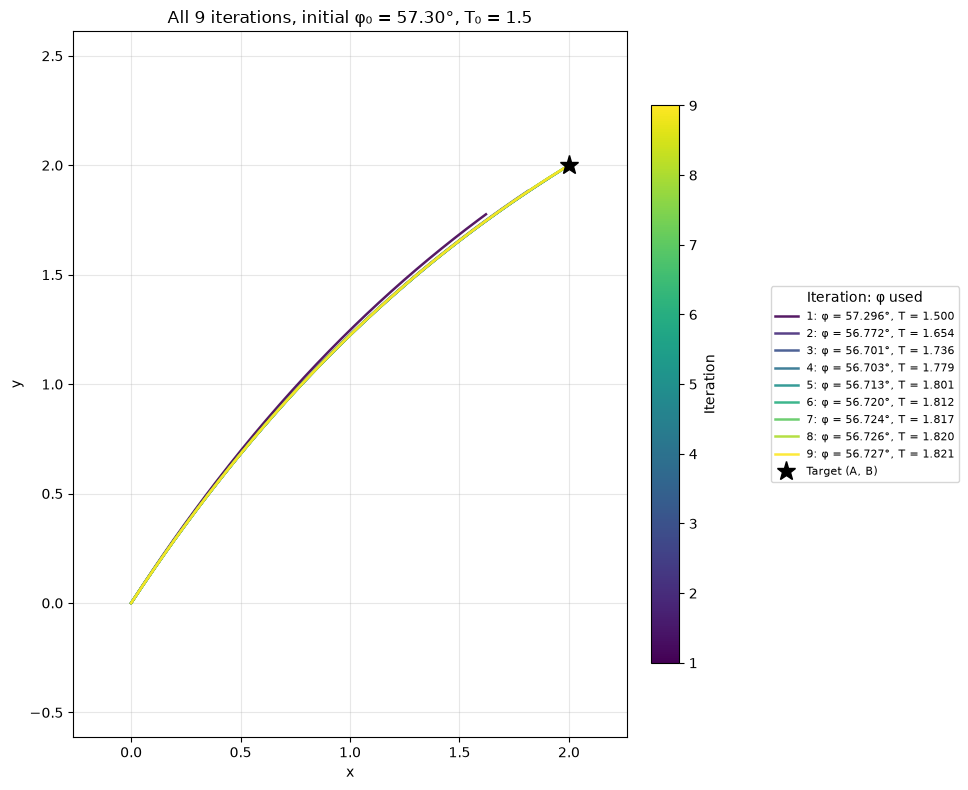

In [35]:
from matplotlib import cm, colors
from scipy.integrate import solve_ivp

"""
v = -cy
u = 0
"""

c = 0.5
u = lambda t,x,y: 0.0
v = lambda t,x,y: -c*y
k = 2.0
A, B = 2, 2
phi0 = 1.0 # 57 deg


# phi_opt = 32.75  # degrees
# deviation = 35.0  # degrees
# phi0 = (phi_opt + deviation) / 180 * np.pi # initial guess for init angle

T0 = 1.5 # initial guess for final time

trajectory, losses, params, num_iters = deepen(
    num=10, phi_init=phi0, T_init=T0
)

print('params:', params)

Tstar = params[num_iters-1, 1]
phistar = params[num_iters-1, 0] # best ones according to algo
x_best, y_best = trajectory[-1]
#phi_best = np.atan2(y_best / x_best) if x_best != 0 else np.pi / 2
fig, ax = plt.subplots(figsize=(10, 8))

print('phistar, Tstar:', phistar, Tstar)
print('best time:', Tstar)

cmap = cm.viridis
norm = colors.Normalize(vmin=1, vmax=max(num_iters, 2))

# every iteration, colored by its iteration number and labelled with its phi
k = 0
"""

ax.plot(x, y, color=cmap(norm(k + 1)), lw=1.8, alpha=0.9,
                label=f"{k + 1}: φ = {180/np.pi*phi:.3f}°, T = {T:.3f}")
        k += 1
        """
for k in range(num_iters):
    x, y = trajectory[k]
    phi_k, T_k = params[k, :]
    ax.plot(x, y, color=cmap(norm(k + 1)), lw=1.8, alpha=0.9,
            label=f"{k + 1}: φ = {180/np.pi*phi_k:.3f}°, T = {T_k:.3f}")

        

# start point and target
#ax.plot(paths[0][0][0], paths[0][1][0], "go", markersize=8, label="Start")
ax.plot(A, B, "k*", markersize=14, label="Target (A, B)")

# colorbar for the iteration number
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, label="Iteration", fraction=0.046, pad=0.04)

ax.set_title(f"All {num_iters} iterations, initial φ₀ = {180/np.pi*phi0:.2f}°, T₀ = {T0}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

# legend outside the axes, to the right of the colorbar
ax.legend(title="Iteration: φ used", loc="center left",
          bbox_to_anchor=(1.25, 0.5), fontsize=8)

fig.tight_layout()
plt.show()